# Semana 3. Ajuste de hiperparámetros de CNN con Fashion-MNIST
### TensorFlow + Keras Tuner (Hyperband) · PyTorch Lightning + Optuna (Random Search)

**Objetivos.** Comparar dos métodos de búsqueda con la **misma arquitectura conceptual**, las mismas imágenes y la misma partición de entrenamiento/validación/prueba.
**Flujo:** datos → CNN parametrizada → búsqueda → mejor configuración → reentrenamiento → evaluación en test.

In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
import pandas as pd
print("TensorFlow:", tf.__version__)

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.21.0


In [5]:
!pip install keras-tuner -q

import keras_tuner as kt

In [7]:
%pip install -q importlib-resources

In [8]:

  (ds_train_raw, ds_val_raw, ds_test_raw), ds_info = tfds.load(
    name="fashion_mnist",
    split=[
        "train[:40%]",
        "train[40%:50%]",
        "test[:50%]"
    ],
    shuffle_files=True,
    as_supervised=True,
    with_info=True
)

NUM_CLASSES = ds_info.features["label"].num_classes
CLASS_NAMES = [str(i) for i in range(NUM_CLASSES)]

print(ds_info)
print("Número de clases:", NUM_CLASSES)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.V1J476_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.V1J476_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='fashion_mnist',
    full_name='fashion_mnist/3.0.1',
    description="""
    Fashion-MNIST is a dataset of Zalando's article images consisting of a training set of 60,000 examples and a test set of 10,000 examples. Each example is a 28x28 grayscale image, associated with a label from 10 classes.
    """,
    homepage='https://github.com/zalandoresearch/fashion-mnist',
    data_dir='/root/tensorflow_datasets/fashion_mnist/3.0.1',
    file_format=tfrecord,
    download_size=29.45 MiB,
    dataset_size=36.42 MiB,
    features=FeaturesDict({
        'image': Image(shape=(28, 28, 1), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=

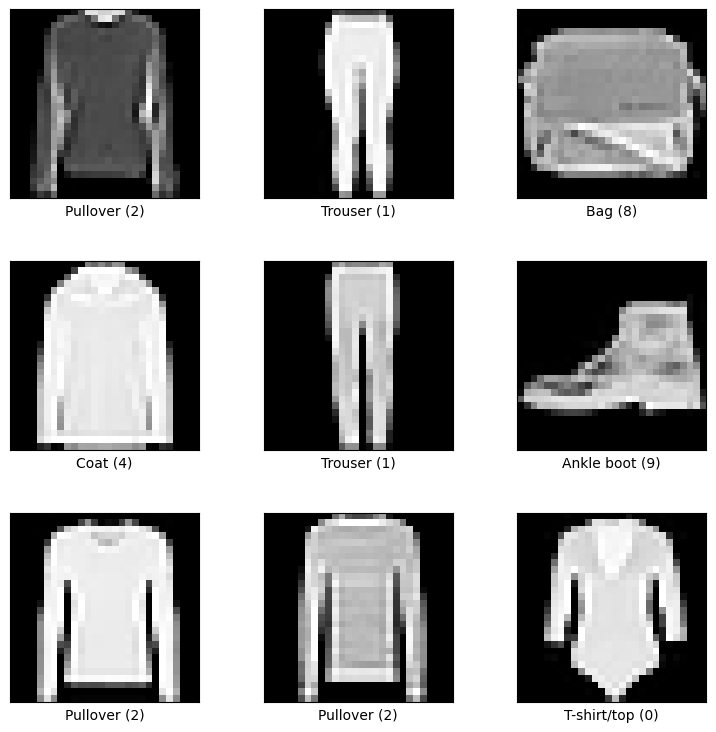

In [9]:
fig = tfds.show_examples(ds_train_raw, ds_info)

In [10]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.int32)

def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    return image, label

def make_dataset(raw, training=False):
    ds = raw.map(preprocess, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(ds_train_raw, training=True)
val_ds = make_dataset(ds_val_raw)
test_ds = make_dataset(ds_test_raw)
for x_batch, y_batch in train_ds.take(1):
    print('x:', x_batch.shape, x_batch.dtype, '| y:', y_batch.shape, y_batch.dtype)
    print('Rango de píxeles:', float(tf.reduce_min(x_batch)), float(tf.reduce_max(x_batch)))

x: (32, 28, 28, 1) <dtype: 'float32'> | y: (32,) <dtype: 'int32'>
Rango de píxeles: 0.0 1.0


##  TensorFlow / Keras Tuner: Hyperband
https://keras.io/keras_tuner/api/hyperparameters/#int-method

Hyperband empieza con varios candidatos y asigna más épocas a los más prometedores.

In [12]:
SEARCH_SPACE = {
    "learning_rate": [1e-2, 1e-3],
    "dropout": [0.5, 0.2],
    "filters": [8, 16],
    "activation": ["relu", "elu"],
}


def build_tf_model(hp):

    filters = hp.Choice("filters", SEARCH_SPACE["filters"])
    activation = hp.Choice("activation", SEARCH_SPACE["activation"])
    dropout = hp.Choice("dropout", SEARCH_SPACE["dropout"])
    lr = hp.Choice("learning_rate", SEARCH_SPACE["learning_rate"])

    inputs = tf.keras.Input(shape=(28, 28, 1))
    x = inputs

    n_layers = hp.Int("conv_layers", min_value=1, max_value=3)
    for i in range(n_layers):
        x = tf.keras.layers.Conv2D(
            filters=filters,
            kernel_size=hp.Int(f"kernel_size_{i}", 3, 5, step=2),
            activation=activation,
            padding="same",
            name=f"conv_{i}",
        )(x)

        pool = hp.Choice(f"pooling_{i}", ["max", "avg"])
        Pool = tf.keras.layers.MaxPooling2D if pool == "max" else tf.keras.layers.AveragePooling2D
        x = Pool(pool_size=2, name=f"{pool}pool_{i}")(x)

        x = tf.keras.layers.BatchNormalization(name=f"bn_{i}")(x)
        if hp.Boolean("dropout"):
            x = tf.keras.layers.Dropout(dropout, name=f"drop_{i}")(x)


    gpool = hp.Choice("global_pooling", ["max", "avg"])
    GPool = tf.keras.layers.GlobalMaxPooling2D if gpool == "max" else tf.keras.layers.GlobalAveragePooling2D
    x = GPool(name=f"global_{gpool}")(x)

    outputs = tf.keras.layers.Dense(10, activation="softmax", name="probs")(x)

    model = tf.keras.Model(inputs, outputs, name="cnn_tunable")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [13]:
MAX_EPOCHS = 5
tuner = kt.Hyperband(
    build_tf_model, objective='val_accuracy',
    max_epochs=MAX_EPOCHS, factor=3, hyperband_iterations=1,
    directory='tuning_results', project_name='tf_hyperband_fashion',
    overwrite=True, seed=SEED)
tuner.search_space_summary()

Search space summary
Default search space size: 8
filters (Choice)
{'default': 8, 'conditions': [], 'values': [8, 16], 'ordered': True}
activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'elu'], 'ordered': False}
dropout (Choice)
{'default': 0.5, 'conditions': [], 'values': [0.5, 0.2], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001], 'ordered': True}
conv_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
kernel_size_0 (Int)
{'default': None, 'conditions': [], 'min_value': 3, 'max_value': 5, 'step': 2, 'sampling': 'linear'}
pooling_0 (Choice)
{'default': 'max', 'conditions': [], 'values': ['max', 'avg'], 'ordered': False}
global_pooling (Choice)
{'default': 'max', 'conditions': [], 'values': ['max', 'avg'], 'ordered': False}


In [15]:
tuner.search(train_ds, validation_data=val_ds,
             batch_size=BATCH_SIZE, verbose=1)
best_hp = tuner.get_best_hyperparameters(1)[0]
best_tf_params = {k: best_hp.get(k) for k in SEARCH_SPACE}
print('Mejor Hyperband:', best_tf_params)

Trial 10 Complete [00h 02m 21s]
val_accuracy: 0.828000009059906

Best val_accuracy So Far: 0.828000009059906
Total elapsed time: 00h 14m 11s
Mejor Hyperband: {'learning_rate': 0.001, 'dropout': 0.2, 'filters': 16, 'activation': 'relu'}


In [16]:
import pandas as pd
import numpy as np


def trials_to_dataframe(tuner, sort_by="score", ascending=False):

    rows = []
    for trial in tuner.oracle.trials.values():
        hps = trial.hyperparameters.values.copy()

        metrics = {}
        if trial.metrics is not None:
            for name, values in trial.metrics.metrics.items():
                if name.startswith("val_"):
                    metrics[name] = values.get_best_value()

            for name, values in trial.metrics.metrics.items():
                if not name.startswith("val_"):
                    metrics[name] = values.get_best_value()


        rows.append({
            "status": trial.status,
            "score": trial.score,
            "best_step": getattr(trial, "best_step", np.nan),
            **hps,
            **metrics,
        })

    df = pd.DataFrame(rows)
    if sort_by in df.columns:
        df = df.sort_values(sort_by, ascending=ascending, na_position="last")
    return df.reset_index(drop=True)

In [17]:
trials_to_dataframe(tuner)

,status,score,best_step,filters,activation,dropout,learning_rate,conv_layers,kernel_size_0,pooling_0,...,tuner/round,kernel_size_1,pooling_1,kernel_size_2,pooling_2,val_accuracy,val_loss,accuracy,loss,tuner/trial_id
0,COMPLETED,0.828000,3,16,relu,0.2,0.001,2,3,avg,...,0,5,max,3,max,0.828000,0.478710,0.814542,0.541432,NaN
1,COMPLETED,0.809000,2,16,relu,0.5,0.001,3,3,max,...,1,3,max,5,max,0.809000,0.504733,0.751500,0.671125,0003
2,COMPLETED,0.754333,1,16,relu,0.5,0.001,3,3,max,...,0,3,max,5,max,0.754333,0.632405,0.703000,0.817547,NaN
3,COMPLETED,0.735500,2,16,relu,0.5,0.010,3,3,avg,...,1,3,max,3,max,0.735500,0.747129,0.678333,0.846942,0000
4,COMPLETED,0.721833,1,16,relu,0.5,0.010,3,3,avg,...,0,3,max,3,max,0.721833,0.778133,0.642542,0.935678,NaN
5,COMPLETED,0.714833,1,8,relu,0.2,0.001,3,3,avg,...,0,5,max,3,max,0.714833,0.807251,0.672458,0.920776,NaN
6,COMPLETED,0.645000,4,16,elu,0.5,0.010,1,5,avg,...,0,5,avg,5,max,0.645000,1.073801,0.640917,1.014701,NaN
7,COMPLETED,0.639500,3,8,relu,0.5,0.001,1,5,avg,...,0,5,max,3,max,0.639500,1.062990,0.588250,1.142658,NaN
8,COMPLETED,0.617833,1,16,relu,0.5,0.010,1,3,max,...,0,5,avg,3,max,0.617833,1.052512,0.615167,1.071411,NaN
9,COMPLETED,0.610667,1,16,relu,0.5,0.010,1,3,avg,...,0,5,max,3,max,0.610667,1.076045,0.584458,1.131347,NaN


In [18]:
models = tuner.get_best_models(num_models=2)
best_model = models[0]
best_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "cnn_tunable"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_0 (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avgpool_0 (AveragePooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_0 (BatchNormalization)       │ (None, 14, 14, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_0 (Dropout)                │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 14, 14, 16)     │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling2D)        │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 7, 7, 16)       │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg                      │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,874 (26.85 KB)

 Trainable params: 6,810 (26.60 KB)

 Non-trainable params: 64 (256.00 B)

Reentrenamiento de la mejor configuración y evaluación en TEST
Para ambos frameworks se vuelve a entrenar desde cero la configuración seleccionada usando únicamente el subconjunto **train**, vigilando `val`. Después se consulta el test oficial **una sola vez** por implementación.

In [19]:
history_tf = best_model.fit(
    train_ds, validation_data=val_ds,
    batch_size=BATCH_SIZE, epochs=MAX_EPOCHS, verbose=1)
tf_test_loss, tf_test_acc = best_model.evaluate(test_ds, verbose=1)
print(f'TensorFlow test accuracy: {tf_test_acc:.4f}')

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 29s 37ms/step - accuracy: 0.8215 - loss: 0.5087 - val_accuracy: 0.8400 - val_loss: 0.4574
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 27s 36ms/step - accuracy: 0.8296 - loss: 0.4860 - val_accuracy: 0.8125 - val_loss: 0.5094
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 28s 37ms/step - accuracy: 0.8325 - loss: 0.4705 - val_accuracy: 0.8342 - val_loss: 0.4695
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.8357 - loss: 0.4611 - val_accuracy: 0.8347 - val_loss: 0.4705
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 28s 37ms/step - accuracy: 0.8418 - loss: 0.4485 - val_accuracy: 0.8443 - val_loss: 0.4346
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.8392 - loss: 0.4447
TensorFlow test accuracy: 0.8392


## 3. PyTorch Lightning + Optuna: Random Search
Se utilizan los mismos arrays, la misma forma de CNN, Adam, entropía cruzada y el mismo espacio discreto de cuatro hiperparámetros. `RandomSampler` prueba combinaciones aleatorias **sin utilizar los resultados anteriores para proponerlas**. No activamos pruning para conservar el carácter de Random Search.

https://optuna.org/

In [21]:
%pip install -q lightning

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 27.3 MB/s eta 0:00:00


In [22]:
import lightning as L

print("Lightning version:", L.__version__)

Lightning version: 2.6.6


In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import lightning as L
from torchvision.datasets import FashionMNIST
import torchvision.transforms as T
from torch.utils.data import random_split
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
SEED = 42

In [ ]:
%pip install optuna

In [27]:
%pip install -q "optuna-integration[pytorch_lightning]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.2/88.2 kB 1.8 MB/s eta 0:00:00


In [28]:
import optuna
from optuna_integration import PyTorchLightningPruningCallback

print("Optuna version:", optuna.__version__)
print("Lightning pruning callback imported successfully.")

Optuna version: 5.0.0
Lightning pruning callback imported successfully.


In [29]:
import optuna
from optuna.integration import PyTorchLightningPruningCallback

/usr/lib/python3.13/importlib/__init__.py:88: FutureWarning: `optuna.integration.pytorch_lightning` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `optuna_integration.pytorch_lightning` instead.
  return _bootstrap._gcd_import(name[level:], package, level)


In [ ]:
## EL METODO ANTERIOR SERA DEPRECADO. REEMPLAZAR PARA FUTURAS IMPLEMENTACIONES ( CURSOS FUTUROS )
## from optuna.integration import PyTorchLightningPruningCallback
## from optuna_integration.pytorch_lightning import PyTorchLightningPruningCallback
## import optuna
## from optuna_integration.pytorch_lightning import PyTorchLightningPruningCallback

In [31]:
base_transform = T.Compose([
    T.ToTensor(),
])

train_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.ToTensor(),
])

val_transform = base_transform
test_transform = base_transform

In [32]:
train_ds_full = FashionMNIST(root="./data", train=True,  download=True,
                        transform=train_transform)
test_ds_full  = FashionMNIST(root="./data", train=False, download=True,
                        transform=val_transform)

from torch.utils.data import Subset
N = 1000
train_ds = Subset(train_ds_full, range(N*10))
test_ds = Subset(test_ds_full, range(N))

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 304kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.65MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.5MB/s]


In [33]:

val_size   = int(0.1 * len(train_ds))
train_size = len(train_ds) - val_size
train_ds, val_ds = random_split(
    train_ds, [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

In [34]:
BATCH_SIZE=32
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False)
x_batch, y_batch = next(iter(train_loader))
print("x:", x_batch.shape, x_batch.dtype, "| y:", y_batch.shape, y_batch.dtype)
print("Rango de píxeles:", float(x_batch.min()), float(x_batch.max()))

x: torch.Size([32, 1, 28, 28]) torch.float32 | y: torch.Size([32]) torch.int64
Rango de píxeles: 0.0 1.0


In [35]:
class LitCNN(L.LightningModule):
    def __init__(self, num_classes=10, lr = 1e-3, dropout = 0.3,
                 base_filters=16):
        super().__init__()
        self.save_hyperparameters()

        self.features = nn.Sequential(
            nn.Conv2d(1, base_filters, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_filters),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(base_filters, base_filters * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_filters * 2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(base_filters * 2, base_filters * 4, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_filters * 4),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base_filters * 4, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

    def _step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = F.cross_entropy(logits, y)
        acc = (logits.argmax(dim=1) == y).float().mean()
        self.log(f'{stage}_loss', loss, on_epoch=True, on_step=False,
                 prog_bar=(stage != 'train'), batch_size=x.size(0))
        self.log(f'{stage}_accuracy', acc, on_epoch=True, on_step=False,
                 prog_bar=True, batch_size=x.size(0))
        return loss

    def training_step(self, batch, _):
        return self._step(batch, "train")

    def validation_step(self, batch, _):
        self._step(batch, "val")

    def test_step(self, batch, _):
        self._step(batch, "test")

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.parameters(),
            lr=self.hparams.lr)

In [36]:
def objective(trial):
    lr           = trial.suggest_float("lr", 1e-3, 1e-2, log=True)
    dropout      = trial.suggest_float("dropout", 0.0, 0.3, step=0.1)
    base_filters = trial.suggest_categorical("base_filters", [8,16, 32])

    model = LitCNN(lr=lr, dropout=dropout, base_filters=base_filters)

    callbacks = [
        L.pytorch.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=3),
        PyTorchLightningPruningCallback(trial, monitor="val_accuracy"),
    ]

    trainer = L.Trainer(max_epochs=5,callbacks=callbacks)
    trainer.fit(model, train_loader, val_loader)
    return trainer.callback_metrics["val_accuracy"].item()

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.RandomSampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner())

study.optimize(objective, n_trials=5, timeout=None)

print("Best val_accuracy:", study.best_value)
print("Best params :", study.best_params)

[I 2026-10-23 13:22:32,183] A new study created in memory with name: no-name-1256fe8d-13b6-44ac-b348-2485919e6734
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable

┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name       ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ features   │ Sequential │  6.0 K │ train │     0 │
│ 1 │ classifier │ Sequential │    330 │ train │     0 │
└───┴────────────┴────────────┴────────┴───────┴───────┘

Trainable params: 6.3 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 6.3 K                                                                                                
Total estimated model params size (MB): 0.025                                                                      
Modules in train mode: 17                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

...

Trainable params: 94.4 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 94.4 K                                                                                               
Total estimated model params size (MB): 0.378                                                                      
Modules in train mode: 17                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: `Trainer.fit` stopped: `max_epochs=5` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=5` reached.


[I 2026-10-23 13:28:59,051] Trial 4 finished with value: 0.8230000138282776 and parameters: {'lr': 0.004091220574443786, 'dropout': 0.0, 'base_filters': 32}. Best is trial 4 with value: 0.8230000138282776.


Best val_accuracy: 0.8230000138282776
Best params : {'lr': 0.004091220574443786, 'dropout': 0.0, 'base_filters': 32}


,number,value,params_base_filters,params_dropout,params_lr,state
4,4,0.823,32,0.0,0.004091,COMPLETE
0,0,0.805,8,0.3,0.002369,COMPLETE
1,1,0.796,8,0.0,0.001432,COMPLETE
3,3,0.779,8,0.1,0.001525,COMPLETE
2,2,0.723,8,0.3,0.001049,COMPLETE


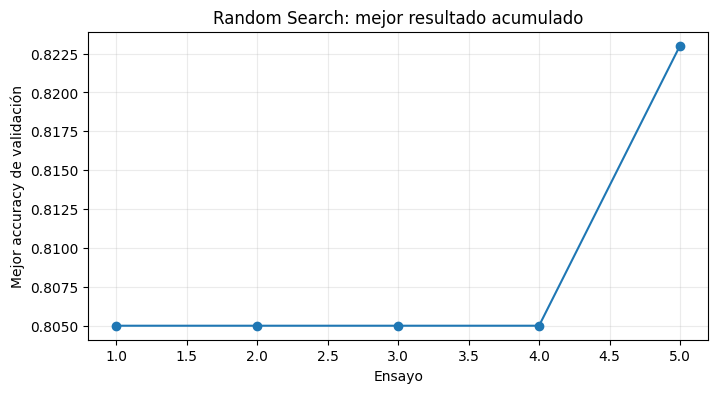

In [37]:
torch_results = study.trials_dataframe(attrs=('number', 'value', 'params', 'state'))
display(torch_results.sort_values('value', ascending=False))
import numpy as np
fig, ax = plt.subplots(figsize=(8, 4))
scores = [t.value for t in study.trials if t.value is not None]
ax.plot(range(1, len(scores)+1), np.maximum.accumulate(scores), marker='o')
ax.set(xlabel='Ensayo', ylabel='Mejor accuracy de validación',
       title='Random Search: mejor resultado acumulado')
ax.grid(alpha=0.25)
plt.show()

In [38]:
best = study.best_params

final_model = LitCNN(
    lr=best["lr"],
    dropout=best["dropout"],
    base_filters=best["base_filters"])

trainer = L.Trainer(
    max_epochs=5,
    callbacks=[L.pytorch.callbacks.EarlyStopping(monitor="val_loss", patience=3, mode="min")],
)
trainer.fit(final_model, train_loader, val_loader)
trainer.test(final_model, test_loader)



INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch.utilities

┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name       ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ features   │ Sequential │ 93.1 K │ train │     0 │
│ 1 │ classifier │ Sequential │  1.3 K │ train │     0 │
└───┴────────────┴────────────┴────────┴───────┴───────┘

Trainable params: 94.4 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 94.4 K                                                                                               
Total estimated model params size (MB): 0.378                                                                      
Modules in train mode: 17                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: `Trainer.fit` stopped: `max_epochs=5` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=5` reached.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test_accuracy       │    0.8309999704360962     │
│         test_loss         │    0.48776528239250183    │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 0.48776528239250183, 'test_accuracy': 0.8309999704360962}]